# Ejercicio 1: Una imagen como matriz y como vector

## Inciso a)

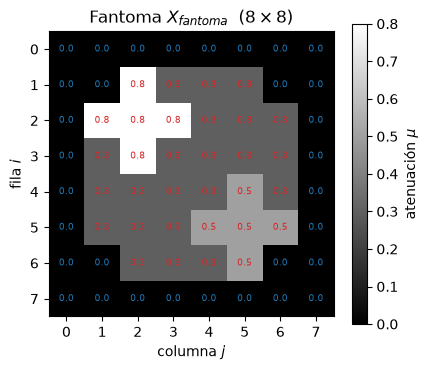

In [20]:
import numpy as np
import matplotlib.pyplot as plt

X_fantoma = np.array([
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
    [0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
    [0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)

n = 8   # la imagen es de n x n píxeles

fig, ax = plt.subplots(figsize=(4.6, 3.9))
im = ax.imshow(X_fantoma, cmap="gray", vmin=0.0, vmax=X_fantoma.max())
ax.set_title(r"Fantoma $X_{fantoma}$  ($8 \times 8$)")
ax.set_xlabel("columna $j$")
ax.set_ylabel("fila $i$")
ax.set_xticks(range(n))
ax.set_yticks(range(n))
for i in range(n):
    for j in range(n):
        v = X_fantoma[i, j]
        ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=6.5,
                color="tab:red" if v > 0 else "tab:blue")
fig.colorbar(im, ax=ax, label=r"atenuación $\mu$")
plt.show()


## Inciso b)

In [21]:
x_fantoma = X_fantoma.reshape(-1)

print("x_fantoma:", x_fantoma.shape)

x_fantoma: (64,)


## Inciso c)


In [22]:
X_fantoma_original = x_fantoma.reshape(8, 8)

print("Es la misma?", np.array_equal(X_fantoma_original, X_fantoma))
print("allclose: ", np.allclose(X_fantoma_original, X_fantoma))

Es la misma? True
allclose:  True


## Inciso d)

La componente $x_k$ es la **atenuación del píxel $k$**: cuánto frena ese material a los rayos X que lo atraviesan. Según su valor:

- **Alto**: material que atenúa mucho, al detector llega poca intensidad. En la imagen se ve claro.
- **Bajo**: material más transparente, el rayo lo atraviesa perdiendo poca intensidad. Se ve gris oscuro.
- **Nulo**: no hay material, el rayo pasa sin atenuarse y el píxel no aporta a ninguna medición. Se ve negro.

Cada detector mide la atenuación acumulada a lo largo de un rayo, o sea la suma de los $x_k$ de los píxeles que ese rayo atraviesa. Por eso los $x_k$ son las incógnitas del sistema $b = Ax$ que queremos resolver.

## Inciso e)

In [23]:
i0, j0 = 3, 5   # pixel elegido

X_modificada = X_fantoma.copy()
X_modificada[i0, j0] = 1.0
x_modificado = X_modificada.reshape(-1)

cambiadas = np.flatnonzero(x_modificado != x_fantoma)
print(f"Modificamos X[3, 5]: {X_fantoma[3, 5]} -> {X_modificada[3, 5]}")
print("componentes de x que cambiaron:", cambiadas)
print("k predicho por la fórmula k = i*n + j:", i0 * n + j0)

Modificamos X[3, 5]: 0.3 -> 1.0
componentes de x que cambiaron: [29]
k predicho por la fórmula k = i*n + j: 29


In [ ]:
# Verificamos la fórmula para los 64 píxeles en los dos sentidos
ok_directa, ok_inversa = True, True
for i in range(n):
    for j in range(n):
        k = i * n + j
        ok_directa &= bool(X_fantoma[i, j] == x_fantoma[k])
        ok_inversa &= (k // n == i) and (k % n == j)

print("k = i*n + j  válida para los 64 píxeles :", ok_directa)
print("i = k // n , j = k % n  válidas para los 64 índices:", ok_inversa)

k = i*n + j  válida para los 64 píxeles : True
i = k // n , j = k % n  válidas para los 64 índices: True


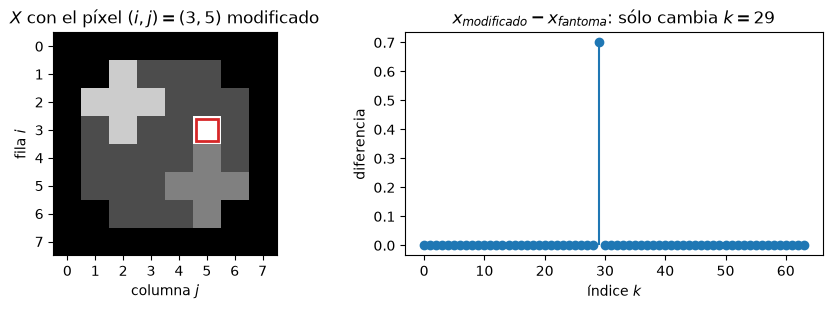

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(9.0, 3.2))

axes[0].imshow(X_modificada, cmap="gray", vmin=0, vmax=1.0)
axes[0].plot(j0, i0, "s", ms=16, mfc="none", mec="tab:red", mew=2)
axes[0].set_title(f"$X$ con el píxel $(i,j)=({i0},{j0})$ modificado")
axes[0].set_xlabel("columna $j$")
axes[0].set_ylabel("fila $i$")
axes[0].set_xticks(range(n))
axes[0].set_yticks(range(n))

axes[1].stem(np.arange(64), x_modificado - x_fantoma, basefmt=" ")
axes[1].set_title(f"$x_{{modificado}} - x_{{fantoma}}$: sólo cambia $k = {i0*n + j0}$")
axes[1].set_xlabel("índice $k$")
axes[1].set_ylabel("diferencia")
fig.tight_layout()
plt.show()